<a href="https://colab.research.google.com/github/Abeer-24/NLP/blob/main/Hybrid_Probabilistic_%2B_FSM_Based_Sequence_Modeling_for_document_boundary_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import re
import numpy as np
import pandas as pd

In [2]:
text = """
INVOICE
Invoice Number: INV101
Date: 12-10-2026
Customer: Rahul Sharma
Amount: 5000

PAYMENT RECEIPT
Receipt Number: R101
Payment Date: 13-10-2026
Amount Paid: 5000

REPORT
Title: Annual Sales Report
Year: 2026
Total Sales: 150000

INVOICE
Invoice Number: INV102
Date: 15-10-2026
Customer: Amit Kumar
Amount: 7000
"""

lines = [line.strip() for line in text.split("\n") if line.strip()]

print("Input Document Sequence:")
for line in lines:
    print(line)

Input Document Sequence:
INVOICE
Invoice Number: INV101
Date: 12-10-2026
Customer: Rahul Sharma
Amount: 5000
PAYMENT RECEIPT
Receipt Number: R101
Payment Date: 13-10-2026
Amount Paid: 5000
REPORT
Title: Annual Sales Report
Year: 2026
Total Sales: 150000
INVOICE
Invoice Number: INV102
Date: 15-10-2026
Customer: Amit Kumar
Amount: 7000


In [3]:
document_headers = [
    "INVOICE",
    "PAYMENT RECEIPT",
    "REPORT"
]

def probability_of_boundary(line):
    line_upper = line.upper()

    if line_upper in document_headers:
        return 0.95

    if re.search(r"^(invoice|receipt|report)\s*(number|no\.|id)", line, re.I):
        return 0.70

    return 0.05

print("Probabilistic Boundary Detection:")

for line in lines:
    probability = probability_of_boundary(line)
    print(line, "->", round(probability, 2))

Probabilistic Boundary Detection:
INVOICE -> 0.95
Invoice Number: INV101 -> 0.7
Date: 12-10-2026 -> 0.05
Customer: Rahul Sharma -> 0.05
Amount: 5000 -> 0.05
PAYMENT RECEIPT -> 0.95
Receipt Number: R101 -> 0.7
Payment Date: 13-10-2026 -> 0.05
Amount Paid: 5000 -> 0.05
REPORT -> 0.95
Title: Annual Sales Report -> 0.05
Year: 2026 -> 0.05
Total Sales: 150000 -> 0.05
INVOICE -> 0.95
Invoice Number: INV102 -> 0.7
Date: 15-10-2026 -> 0.05
Customer: Amit Kumar -> 0.05
Amount: 7000 -> 0.05


In [4]:
OUTSIDE = "OUTSIDE"
INVOICE = "INVOICE"
RECEIPT = "RECEIPT"
REPORT = "REPORT"

def fsm_detector(line, current_state):
    line_upper = line.upper()

    if line_upper == "INVOICE":
        return INVOICE, True

    elif line_upper == "PAYMENT RECEIPT":
        return RECEIPT, True

    elif line_upper == "REPORT":
        return REPORT, True

    return current_state, False


state = OUTSIDE

print("FSM Boundary Detection:")

for line in lines:
    state, boundary = fsm_detector(line, state)
    print(line, "-> State:", state, "| Boundary:", boundary)

FSM Boundary Detection:
INVOICE -> State: INVOICE | Boundary: True
Invoice Number: INV101 -> State: INVOICE | Boundary: False
Date: 12-10-2026 -> State: INVOICE | Boundary: False
Customer: Rahul Sharma -> State: INVOICE | Boundary: False
Amount: 5000 -> State: INVOICE | Boundary: False
PAYMENT RECEIPT -> State: RECEIPT | Boundary: True
Receipt Number: R101 -> State: RECEIPT | Boundary: False
Payment Date: 13-10-2026 -> State: RECEIPT | Boundary: False
Amount Paid: 5000 -> State: RECEIPT | Boundary: False
REPORT -> State: REPORT | Boundary: True
Title: Annual Sales Report -> State: REPORT | Boundary: False
Year: 2026 -> State: REPORT | Boundary: False
Total Sales: 150000 -> State: REPORT | Boundary: False
INVOICE -> State: INVOICE | Boundary: True
Invoice Number: INV102 -> State: INVOICE | Boundary: False
Date: 15-10-2026 -> State: INVOICE | Boundary: False
Customer: Amit Kumar -> State: INVOICE | Boundary: False
Amount: 7000 -> State: INVOICE | Boundary: False


In [5]:
def hybrid_boundary_detection(lines, threshold=0.5):
    state = OUTSIDE
    results = []

    for line in lines:
        probability = probability_of_boundary(line)

        state, fsm_boundary = fsm_detector(line, state)

        # Combine probabilistic and FSM decisions
        final_boundary = (
            probability >= threshold or fsm_boundary
        )

        results.append({
            "Line": line,
            "Probability": probability,
            "FSM Boundary": fsm_boundary,
            "Final Boundary": final_boundary,
            "Document Type": state
        })

    return pd.DataFrame(results)


results = hybrid_boundary_detection(lines)

print(results.to_string(index=False))

                      Line  Probability  FSM Boundary  Final Boundary Document Type
                   INVOICE         0.95          True            True       INVOICE
    Invoice Number: INV101         0.70         False            True       INVOICE
          Date: 12-10-2026         0.05         False           False       INVOICE
    Customer: Rahul Sharma         0.05         False           False       INVOICE
              Amount: 5000         0.05         False           False       INVOICE
           PAYMENT RECEIPT         0.95          True            True       RECEIPT
      Receipt Number: R101         0.70         False            True       RECEIPT
  Payment Date: 13-10-2026         0.05         False           False       RECEIPT
         Amount Paid: 5000         0.05         False           False       RECEIPT
                    REPORT         0.95          True            True        REPORT
Title: Annual Sales Report         0.05         False           False       

In [6]:
documents = []
current_document = []

for _, row in results.iterrows():

    if row["Final Boundary"] and current_document:
        documents.append(current_document)
        current_document = []

    current_document.append(row["Line"])

if current_document:
    documents.append(current_document)


print("Detected Documents:")

for i, document in enumerate(documents, 1):
    print(f"\nDocument {i}:")
    print("\n".join(document))

Detected Documents:

Document 1:
INVOICE

Document 2:
Invoice Number: INV101
Date: 12-10-2026
Customer: Rahul Sharma
Amount: 5000

Document 3:
PAYMENT RECEIPT

Document 4:
Receipt Number: R101
Payment Date: 13-10-2026
Amount Paid: 5000

Document 5:
REPORT
Title: Annual Sales Report
Year: 2026
Total Sales: 150000

Document 6:
INVOICE

Document 7:
Invoice Number: INV102
Date: 15-10-2026
Customer: Amit Kumar
Amount: 7000


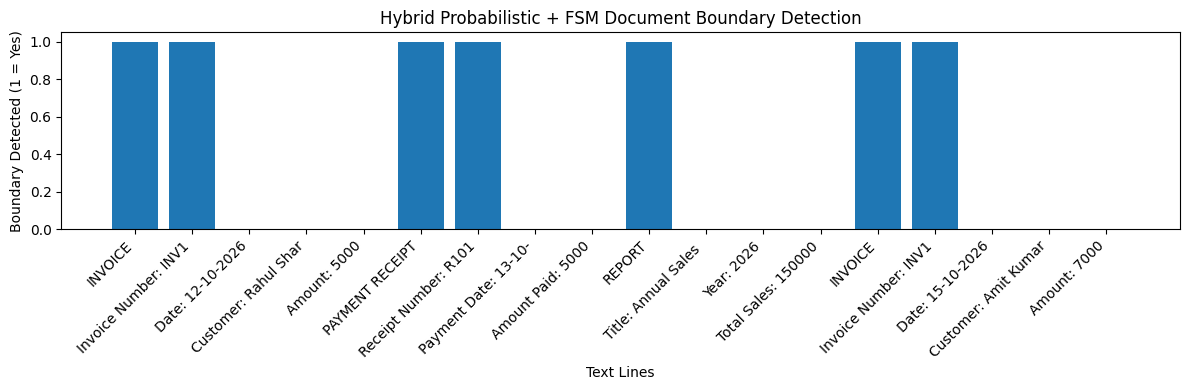

In [7]:
import matplotlib.pyplot as plt

boundary_values = results["Final Boundary"].astype(int)

plt.figure(figsize=(12, 4))

plt.bar(range(len(lines)), boundary_values)

plt.xticks(
    range(len(lines)),
    [line[:20] for line in lines],
    rotation=45,
    ha="right"
)

plt.xlabel("Text Lines")
plt.ylabel("Boundary Detected (1 = Yes)")
plt.title("Hybrid Probabilistic + FSM Document Boundary Detection")
plt.tight_layout()
plt.show()